# 05 — Error Analysis and Figures

This notebook produces the five key figures for the research paper and performs the full error analysis.

**Figures produced:**
1. `error_stage_by_strategy.png` — Stacked bar: % retrieval vs. generation errors per strategy
2. `correctness_heatmap.png` — Answer correctness score by task_type × strategy
3. `error_type_frequency.png` — Horizontal bar: count of each error type across all strategies
4. `retrieval_precision_by_task.png` — Entity hit rate by strategy × task type
5. `score_distributions.png` — Box plots of all 3 evaluation scores by strategy

All figures are saved to `figures/`.

In [1]:
import sys
sys.path.insert(0, '..')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src.config import PROCESSED_DIR
from src.error_taxonomy import ERROR_TYPES, get_retrieval_error_types, get_generation_error_types

FIGURES_DIR = '../figures'
os.makedirs(FIGURES_DIR, exist_ok=True)

# Load data
eval_df = pd.read_csv(os.path.join(PROCESSED_DIR, 'evaluation_results.csv'))
questions_df = pd.read_csv(os.path.join(PROCESSED_DIR, 'questions.csv'))

# Merge task_type into eval_df if not already present
if 'task_type' not in eval_df.columns:
    eval_df = eval_df.merge(questions_df[['question_id', 'task_type']], on='question_id', how='left')

print(f"Evaluation rows: {len(eval_df)}")
print(f"Strategies: {eval_df['strategy'].unique()}")
print(f"Task types: {eval_df['task_type'].unique()}")

STRATEGY_COLORS = {
    'vanilla': '#4878CF',
    'metadata_filtered': '#6ACC65',
    'task_aware': '#D65F5F',
}
STRATEGY_LABELS = {
    'vanilla': 'Vanilla',
    'metadata_filtered': 'Metadata Filtered',
    'task_aware': 'Task-Aware',
}
sns.set_style('whitegrid')
plt.rcParams['font.size'] = 11

Evaluation rows: 120
Strategies: ['vanilla' 'metadata_filtered' 'task_aware']
Task types: ['single_fact' 'risk_factor' 'cross_year' 'cross_company']


## Figure 1 — Error Stage Distribution by Strategy

Shows what fraction of errors come from retrieval vs. generation failures for each strategy.

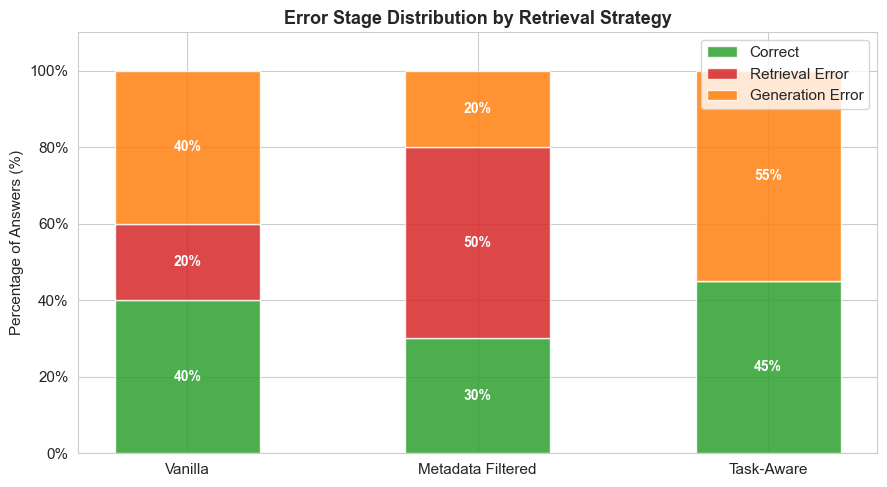

Saved: figures/error_stage_by_strategy.png


In [2]:
stage_counts = eval_df.groupby(['strategy', 'error_stage']).size().reset_index(name='count')
stage_totals = stage_counts.groupby('strategy')['count'].transform('sum')
stage_counts['pct'] = stage_counts['count'] / stage_totals * 100

stage_pivot = stage_counts.pivot(index='strategy', columns='error_stage', values='pct').fillna(0)
# Ensure all columns exist
for col in ['retrieval', 'generation', 'none']:
    if col not in stage_pivot.columns:
        stage_pivot[col] = 0.0

fig, ax = plt.subplots(figsize=(9, 5))

strategies = ['vanilla', 'metadata_filtered', 'task_aware']
strategies = [s for s in strategies if s in stage_pivot.index]
x = np.arange(len(strategies))
width = 0.5

bottom_vals = np.zeros(len(strategies))
stage_colors = {'none': '#2ca02c', 'retrieval': '#d62728', 'generation': '#ff7f0e'}
stage_order = ['none', 'retrieval', 'generation']
stage_labels_map = {'none': 'Correct', 'retrieval': 'Retrieval Error', 'generation': 'Generation Error'}

for stage in stage_order:
    vals = [stage_pivot.loc[s, stage] if s in stage_pivot.index else 0 for s in strategies]
    ax.bar(x, vals, width, bottom=bottom_vals, label=stage_labels_map[stage],
           color=stage_colors[stage], alpha=0.85, edgecolor='white')
    for i, (v, b) in enumerate(zip(vals, bottom_vals)):
        if v > 5:
            ax.text(x[i], b + v / 2, f'{v:.0f}%', ha='center', va='center',
                    color='white', fontweight='bold', fontsize=10)
    bottom_vals += np.array(vals)

ax.set_xticks(x)
ax.set_xticklabels([STRATEGY_LABELS.get(s, s) for s in strategies])
ax.set_ylabel('Percentage of Answers (%)')
ax.set_title('Error Stage Distribution by Retrieval Strategy', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'error_stage_by_strategy.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/error_stage_by_strategy.png")

## Figure 2 — Answer Correctness Heatmap

Mean answer_correctness score (0–2) broken down by task type and retrieval strategy.

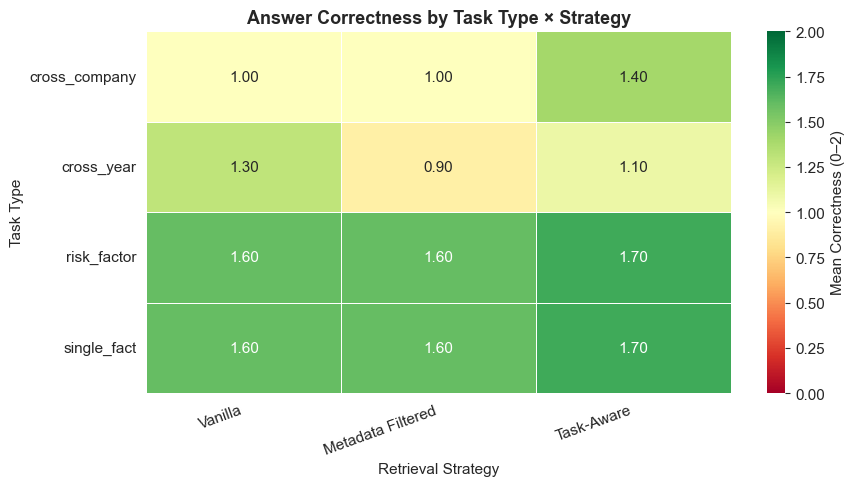

Saved: figures/correctness_heatmap.png


In [3]:
correctness_pivot = eval_df.groupby(['task_type', 'strategy'])['answer_correctness'].mean().reset_index()
correctness_matrix = correctness_pivot.pivot(index='task_type', columns='strategy', values='answer_correctness')

# Reorder columns
col_order = [s for s in ['vanilla', 'metadata_filtered', 'task_aware'] if s in correctness_matrix.columns]
correctness_matrix = correctness_matrix[col_order]
correctness_matrix.columns = [STRATEGY_LABELS.get(c, c) for c in correctness_matrix.columns]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    correctness_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=0, vmax=2, ax=ax,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Mean Correctness (0–2)'}
)
ax.set_title('Answer Correctness by Task Type × Strategy', fontsize=13, fontweight='bold')
ax.set_xlabel('Retrieval Strategy')
ax.set_ylabel('Task Type')
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'correctness_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/correctness_heatmap.png")

## Figure 3 — Error Type Frequency

Overall frequency of each error type, colour-coded by stage (retrieval vs. generation).

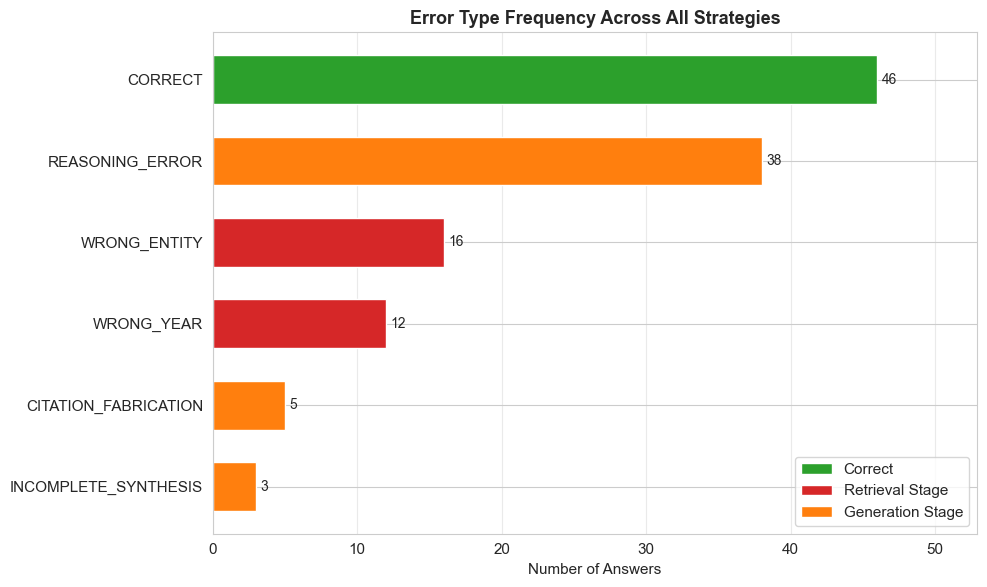

Saved: figures/error_type_frequency.png


In [4]:
error_counts = eval_df['error_type'].value_counts().reset_index()
error_counts.columns = ['error_type', 'count']
error_counts['stage'] = error_counts['error_type'].map(
    lambda e: ERROR_TYPES.get(e, {}).get('stage', 'none')
)
error_counts = error_counts.sort_values('count', ascending=True)

stage_color_map = {'retrieval': '#d62728', 'generation': '#ff7f0e', 'none': '#2ca02c'}
bar_colors = [stage_color_map.get(s, 'gray') for s in error_counts['stage']]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(error_counts['error_type'], error_counts['count'],
               color=bar_colors, edgecolor='white', height=0.6)

for bar, count in zip(bars, error_counts['count']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            str(count), va='center', fontsize=10)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ca02c', label='Correct'),
    Patch(facecolor='#d62728', label='Retrieval Stage'),
    Patch(facecolor='#ff7f0e', label='Generation Stage'),
]
ax.legend(handles=legend_elements, loc='lower right')
ax.set_xlabel('Number of Answers')
ax.set_title('Error Type Frequency Across All Strategies', fontsize=13, fontweight='bold')
ax.set_xlim(0, error_counts['count'].max() * 1.15)
ax.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'error_type_frequency.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/error_type_frequency.png")

## Figure 4 — Retrieval Precision by Task Type

Entity hit rate (expected ticker in top-5) by strategy × task type, loaded from the retrieval results.

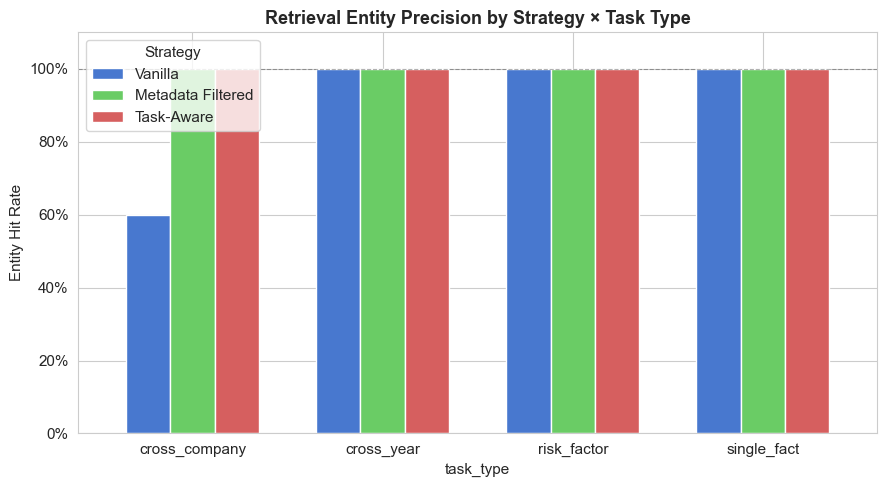

Saved: figures/retrieval_precision_by_task.png


In [5]:
retrieval_path = os.path.join(PROCESSED_DIR, 'retrieval_results.parquet')
retrieval_df = pd.read_parquet(retrieval_path)

# Merge expected ticker
merged = retrieval_df.merge(
    questions_df[['question_id', 'task_type', 'ticker']].rename(columns={'ticker': 'expected_ticker'}),
    on='question_id', how='left'
)

def compute_hit_rate(df):
    result = []
    for (qid, strategy, task_type, expected), group in df.groupby(['question_id', 'strategy', 'task_type', 'expected_ticker']):
        hit = expected in group['ticker'].values
        result.append({'question_id': qid, 'strategy': strategy, 'task_type': task_type, 'hit': hit})
    return pd.DataFrame(result)

hit_df = compute_hit_rate(merged[merged['expected_ticker'].notna()])
hit_pivot = hit_df.groupby(['strategy', 'task_type'])['hit'].mean().reset_index()
hit_matrix = hit_pivot.pivot(index='task_type', columns='strategy', values='hit')

col_order = [s for s in ['vanilla', 'metadata_filtered', 'task_aware'] if s in hit_matrix.columns]
hit_matrix = hit_matrix[col_order]

fig, ax = plt.subplots(figsize=(9, 5))
hit_matrix.plot(kind='bar', ax=ax, rot=0,
                color=[STRATEGY_COLORS.get(c, 'gray') for c in hit_matrix.columns],
                edgecolor='white', width=0.7)
ax.set_ylabel('Entity Hit Rate')
ax.set_title('Retrieval Entity Precision by Strategy × Task Type', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.legend([STRATEGY_LABELS.get(c, c) for c in hit_matrix.columns], title='Strategy')
ax.axhline(1.0, color='black', linestyle='--', alpha=0.3, linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'retrieval_precision_by_task.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/retrieval_precision_by_task.png")

## Figure 5 — Score Distributions

Box plots showing the distribution of all three evaluation scores (correctness, faithfulness, coverage) per strategy.

/var/folders/1y/42jcd32x74sfkj7xjlx937xm0000gn/T/ipykernel_314/3728415789.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/1y/42jcd32x74sfkj7xjlx937xm0000gn/T/ipykernel_314/3728415789.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/1y/42jcd32x74sfkj7xjlx937xm0000gn/T/ipykernel_314/3728415789.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


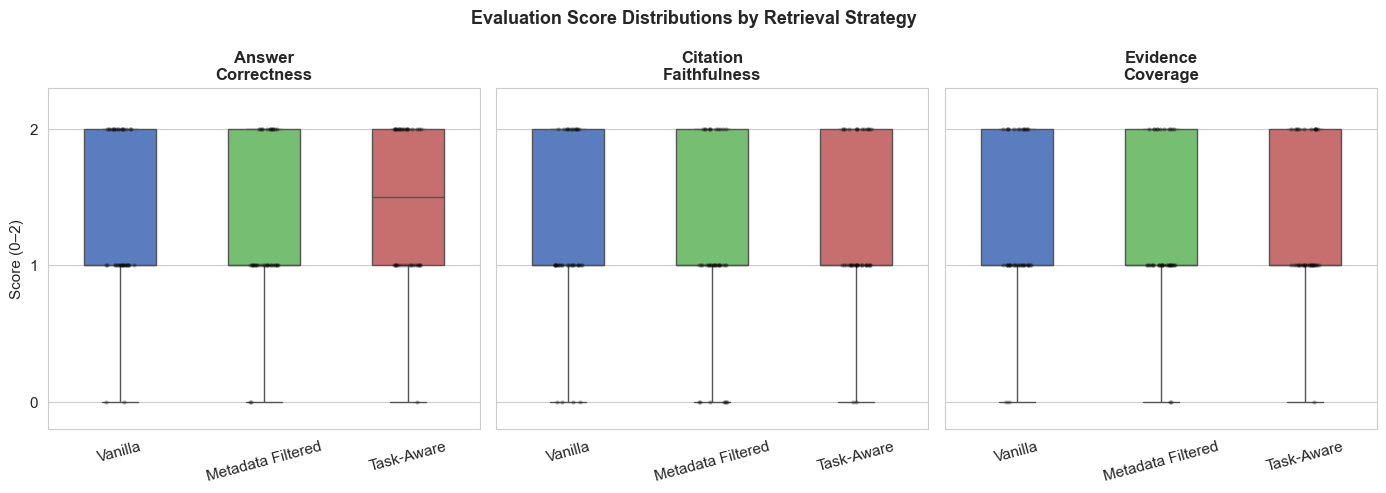

Saved: figures/score_distributions.png


In [6]:
score_cols = ['answer_correctness', 'citation_faithfulness', 'evidence_coverage']
score_labels = {
    'answer_correctness': 'Answer\nCorrectness',
    'citation_faithfulness': 'Citation\nFaithfulness',
    'evidence_coverage': 'Evidence\nCoverage',
}

# Melt into long format
score_df = eval_df[['strategy'] + score_cols].melt(
    id_vars='strategy', var_name='metric', value_name='score'
)
score_df['metric_label'] = score_df['metric'].map(score_labels)
score_df['strategy_label'] = score_df['strategy'].map(STRATEGY_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

for ax, col in zip(axes, score_cols):
    subset = score_df[score_df['metric'] == col]
    strat_order = ['Vanilla', 'Metadata Filtered', 'Task-Aware']
    strat_order = [s for s in strat_order if s in subset['strategy_label'].values]
    
    sns.boxplot(
        data=subset, x='strategy_label', y='score', order=strat_order,
        palette=[STRATEGY_COLORS.get(s, 'gray') for s in ['vanilla', 'metadata_filtered', 'task_aware']],
        ax=ax, width=0.5
    )
    sns.stripplot(
        data=subset, x='strategy_label', y='score', order=strat_order,
        color='black', alpha=0.3, size=3, jitter=True, ax=ax
    )
    ax.set_title(score_labels[col], fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Score (0–2)' if ax == axes[0] else '')
    ax.set_ylim(-0.2, 2.3)
    ax.set_yticks([0, 1, 2])
    ax.tick_params(axis='x', rotation=15)

fig.suptitle('Evaluation Score Distributions by Retrieval Strategy', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'score_distributions.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: figures/score_distributions.png")

## Summary Table

In [7]:
summary = eval_df.groupby('strategy').agg(
    mean_correctness=('answer_correctness', 'mean'),
    mean_faithfulness=('citation_faithfulness', 'mean'),
    mean_coverage=('evidence_coverage', 'mean'),
    pct_correct=('error_type', lambda x: (x == 'CORRECT').mean() * 100),
    pct_retrieval_error=('error_stage', lambda x: (x == 'retrieval').mean() * 100),
    pct_generation_error=('error_stage', lambda x: (x == 'generation').mean() * 100),
).round(2)

summary.index = summary.index.map(STRATEGY_LABELS)
summary.columns = ['Correctness', 'Faithfulness', 'Coverage', '% Correct', '% Retrieval Err', '% Generation Err']

print("\n=== Summary Results ===")
print(summary.to_string())

summary.to_csv(os.path.join(PROCESSED_DIR, 'summary_results.csv'))
print("\nSaved: data/processed/summary_results.csv")


=== Summary Results ===
                   Correctness  Faithfulness  Coverage  % Correct  % Retrieval Err  % Generation Err
strategy                                                                                            
Metadata Filtered         1.27          1.10      1.23       30.0             50.0              20.0
Task-Aware                1.48          1.27      1.30       45.0              0.0              55.0
Vanilla                   1.38          1.23      1.27       40.0             20.0              40.0

Saved: data/processed/summary_results.csv


## Key findings

Use this cell to write up the main takeaways after reviewing the figures above.

In [8]:
# Top errors across all strategies
top_errors = eval_df['error_type'].value_counts().head(5)
print("Top 5 error types overall:")
for etype, count in top_errors.items():
    stage = ERROR_TYPES.get(etype, {}).get('stage', '?')
    desc = ERROR_TYPES.get(etype, {}).get('description', '')
    print(f"  {etype:30s} [{stage:10s}]  n={count}  — {desc}")

print()
# Which strategy has fewest retrieval errors on cross-type tasks
cross_tasks = eval_df[eval_df['task_type'].isin(['cross_year', 'cross_company'])]
print("Retrieval error rate on cross-type tasks by strategy:")
print(cross_tasks.groupby('strategy').apply(
    lambda x: (x['error_stage'] == 'retrieval').mean()
).round(3))

Top 5 error types overall:
  CORRECT                        [none      ]  n=46  — Answer is correct with proper evidence and citations
  REASONING_ERROR                [generation]  n=38  — Evidence is present but model draws wrong conclusion
  WRONG_ENTITY                   [retrieval ]  n=16  — Retrieved chunks from wrong company (ticker mismatch)
  WRONG_YEAR                     [retrieval ]  n=12  — Retrieved chunks from wrong fiscal year
  CITATION_FABRICATION           [generation]  n=5  — Model cites chunk_ids that do not exist in the retrieved set

Retrieval error rate on cross-type tasks by strategy:
strategy
metadata_filtered    1.0
task_aware           0.0
vanilla              0.4
dtype: float64


/var/folders/1y/42jcd32x74sfkj7xjlx937xm0000gn/T/ipykernel_314/1061768255.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(cross_tasks.groupby('strategy').apply(
